## Publish local data as items to your portal

Publishing different file types (.csv, .sd, .shp) of spatial data from your local environment as items in your organization and plotting them on a map in the notebook.

#### Import necessary libraries and connect to GIS

In [1]:
from arcgis.gis import GIS
from arcgis.gis import ItemProperties, ItemTypeEnum
import zipfile
gis = GIS("home")

You are logged on as MMajumdar_geosaurus with an administrator role, proceed with caution.


> NOTE: For following the workflow below, you will need to add your `.sd`, `.shp`, `.csv` files to a folder, zip it, and then add the zipped folder to your Notebook workspace directory. Click [here](https://enterprise.arcgis.com/en/notebook/latest/use/windows/work-with-content-in-a-user-workspace.htm) to learn more about adding content to your workspace.

#### Define variables

In [2]:
path_to_local_data_zip_folder = "<PATH-TO-ZIP-FILE-IN-YOUR-WORKSPACE>"
workspace_directory = "<DIRECTORY-NAME-TO-EXTRACT-FILES>"

#### Unzip the folder with local data

In [3]:
extracted_files = []

with zipfile.ZipFile(path_to_local_data_zip_folder) as archive:
    for file in archive.namelist():
        if file.endswith('.zip') or file.endswith('.sd') or file.endswith('.csv'):
            archive.extract(file, workspace_directory)
            full_path = os.path.join(workspace_directory, file)
            extracted_files.append(full_path)

In [4]:
# Verify expected files are extracted
extracted_files

['extracted_data/local_data/gbr_cities.csv',
 'extracted_data/local_data/set2_points.zip',
 'extracted_data/local_data/WFL_usa.sd']

### Publish sd files as item

#### Define variables

In [5]:
# Titles for sd item
title_sd_item = "<TITLE-FOR-SD-ITEM>"
folder_to_add_item = "<FOLDER-NAME-TO-ADD-DATA>"

<Item title:"WFL USA sd" type:Feature Layer Collection owner:MMajumdar_geosaurus>
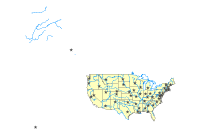

In [6]:
# Fetch folder to add new SD item
my_folder = gis.content.folders.get(folder_to_add_item)

# Fetch the path to the .SD file
sd_file = [file for file in extracted_files if file.endswith('.sd')][0]

# Define item properties
item_properties_sd = ItemProperties(title = title_sd_item, item_type = ItemTypeEnum.SERVICE_DEFINITION)

# Publish as item
job = my_folder.add(item_properties = item_properties_sd, file = sd_file)
item = job.result()
published_sd = item.publish()
published_sd

### Publish shp files as items

#### Define variables

In [7]:
# Titles for .shp item
title_shp_item = "<TITLE-FOR-SHP-ITEM>"
folder_to_add_item = "<FOLDER-NAME-TO-ADD-DATA>"

In [8]:
# Fetch folder to add new SHP item
my_folder = gis.content.folders.get(folder_to_add_item)

# Fetch the path to the .shp file
shp_file = [file for file in extracted_files if file.endswith('.zip')][0]

# Define item properties
item_properties_shp = ItemProperties(title = title_shp_item, item_type = ItemTypeEnum.SHAPEFILE)

# Publish as item
job = my_folder.add(item_properties = item_properties_shp, file = shp_file)
item = job.result()
published_shp = item.publish()
published_shp

<Item title:"set 2 points shp" type:Feature Layer Collection owner:MMajumdar_geosaurus>

### Metadata for newly created items

Adding metadata to data (newly created ArcGIS items) is a good practice to improve quality and credibility of the data. 

In order to do it using the UI, you can go to the item details page of an item (click on the items generated above) and by clicking on the edit pencil icon corresponding to each metadata element, you can update the title, snippet (summary), description, thumbnail, tags, categories and acknowledgement (source) of your data.

You can also use the ArcGIS API for Python to add metadata while creating items by creating an `ItemProperties` object with [supported properties](https://developers.arcgis.com/python/latest/api-reference/arcgis.gis.toc.html#itemproperties). We will see an example to add snippet and description to our CSV item during creation below. 

### Publish csv files as items

#### Define variables

In [13]:
# Titles for .csv item
title_csv_item = "<TITLE-FOR-CSV-ITEM>"
folder_to_add_item = "<FOLDER-NAME-TO-ADD-DATA>"

description = "<DESCRIPTION-FOR-CSV-ITEM>"
tags = "<TAG1>, <TAG2>, <TAG3>"

In [11]:
# Fetch folder to add new CSV item
my_folder = gis.content.folders.get(folder_to_add_item)

# Fetch the path to the .shp file
csv_file = [file for file in extracted_files if file.endswith('.csv')][0]

# Define item properties
item_properties_csv = ItemProperties(title = title_csv_item, item_type = ItemTypeEnum.CSV,
                                    description = description, tags = tags)

# Publish as item
job = my_folder.add(item_properties = item_properties_csv, file = csv_file,  stream=True)
item = job.result()
published_csv = item.publish()
published_csv

<Item title:"global cities csv" type:Feature Layer Collection owner:MMajumdar_geosaurus>

#### Adding these layers to a map

In [25]:
map1 = gis.map()
map1.content.add(published_sd)
map1.content.add(published_shp)
map1.content.add(published_csv)
map1

Map(extent={'type': 'extent', 'xmin': -17999999.999994524, 'ymin': -11999999.999991827, 'xmax': 17999999.99999…

#### Saving this as a map item

#### Define variables

In [26]:
title = "<WEBMAP-ITEM-TITLE>"
snippet = "<WEBMAP-ITEM-SNIPPET>"
tags = "<TAG1>, <TAG2>, <TAG3>"

In [27]:
webmap_ip = {"title":title,
            "snippet":snippet,
            "tags":tags}

map_item = map1.save(webmap_ip)
map_item

<Item title:"Map with local data" type:Web Map owner:MMajumdar_geosaurus>